## IMPORT LIBRARY

In [11]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

LOAD DATASETS

In [12]:
df = pd.read_csv("dataset/olist_orders_dataset.csv")
df2 = pd.read_csv("dataset/olist_order_reviews_dataset.csv")
df3 =pd.read_csv("dataset/olist_order_items_dataset.csv")

In [13]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB
None


In [14]:
print(df2.info())

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 17.8 MB
None


In [15]:
print(df3.info())

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 18.4 MB
None


## CEK MISSING VALUE, DUPLICATED, FEATURE SELECTION

### olist_orders_dataset

In [16]:
print("Missing value olist_orders_dataset:")
print(df.isnull().sum())
print("\nJumlah data duplikat:", df.duplicated().sum())

Missing value olist_orders_dataset:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Jumlah data duplikat: 0


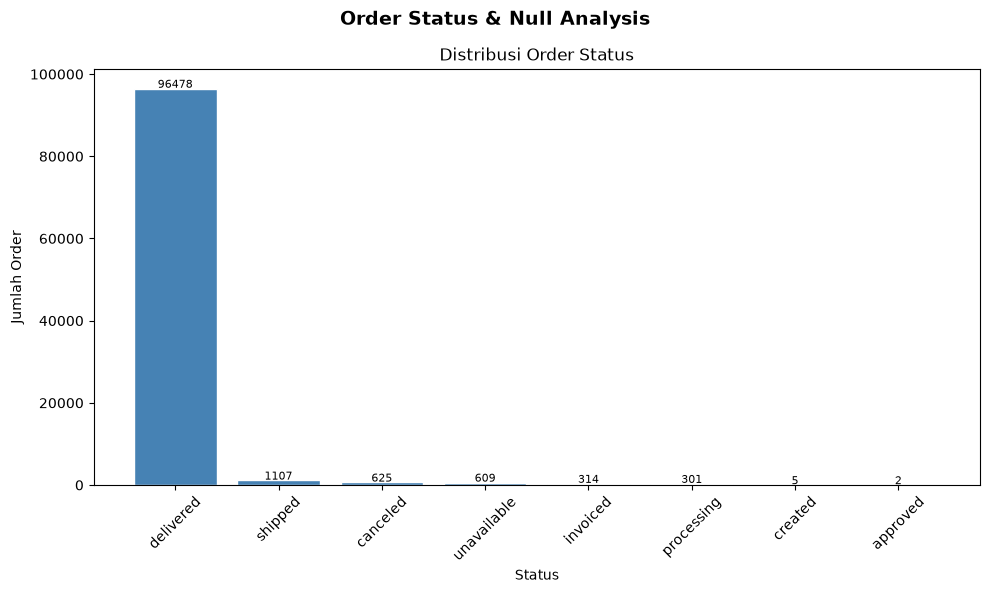

In [31]:
fig, ax = plt.subplots(figsize=(10, 6))
fig.suptitle("Order Status & Null Analysis", fontsize=14, fontweight="bold")

status_counts = df["order_status"].value_counts()

ax.bar(status_counts.index, status_counts.values, color="steelblue", edgecolor="white")
ax.set_title("Distribusi Order Status")
ax.set_xlabel("Status")
ax.set_ylabel("Jumlah Order")
ax.tick_params(axis="x", rotation=45)
for i, v in enumerate(status_counts.values):
    ax.text(i, v + 200, str(v), ha="center", fontsize=8)

plt.tight_layout()
plt.show()

In [28]:
features = ['order_purchase_timestamp', "order_approved_at", "order_delivered_customer_date", "order_estimated_delivery_date"]
df_filtered = df.loc[df["order_status"] == "delivered", features]

In [36]:
print(df_filtered.info())
print("\nCek Null:")
print(df_filtered.isnull().sum())
print("\nCek Duplicated:")
print(df_filtered.duplicated().sum())

<class 'pandas.DataFrame'>
Index: 96478 entries, 0 to 99440
Data columns (total 4 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_purchase_timestamp       96478 non-null  str  
 1   order_approved_at              96464 non-null  str  
 2   order_delivered_customer_date  96470 non-null  str  
 3   order_estimated_delivery_date  96478 non-null  str  
dtypes: str(4)
memory usage: 10.7 MB
None

Cek Null:
order_purchase_timestamp          0
order_approved_at                14
order_delivered_customer_date     8
order_estimated_delivery_date     0
dtype: int64

Cek Duplicated:
0


In [40]:
df_filtered = df_filtered.dropna()
df_filtered.isnull().sum()

order_purchase_timestamp         0
order_approved_at                0
order_delivered_customer_date    0
order_estimated_delivery_date    0
dtype: int64

### olist_order_reviews_dataset

In [17]:
print("Missing value olist_order_reviews_dataset:")
print(df2.isnull().sum())
print("\nJumlah data duplikat:", df2.duplicated().sum())

Missing value olist_order_reviews_dataset:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

Jumlah data duplikat: 0


In [44]:
df2_filtered = df2['review_score']

### olist_order_items_dataset

In [18]:
print("Missing value olist_order_items_dataset:")
print(df3.isnull().sum())
print("\nJumlah data duplikat:", df3.duplicated().sum())

Missing value olist_order_items_dataset:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

Jumlah data duplikat: 0


In [48]:
df3_filtered = df3['shipping_limit_date']

## CEK OUTLIER

In [41]:
print(df3[["price", "freight_value"]].describe())

               price  freight_value
count  112650.000000  112650.000000
mean      120.653739      19.990320
std       183.633928      15.806405
min         0.850000       0.000000
25%        39.900000      13.080000
50%        74.990000      16.260000
75%       134.900000      21.150000
max      6735.000000     409.680000


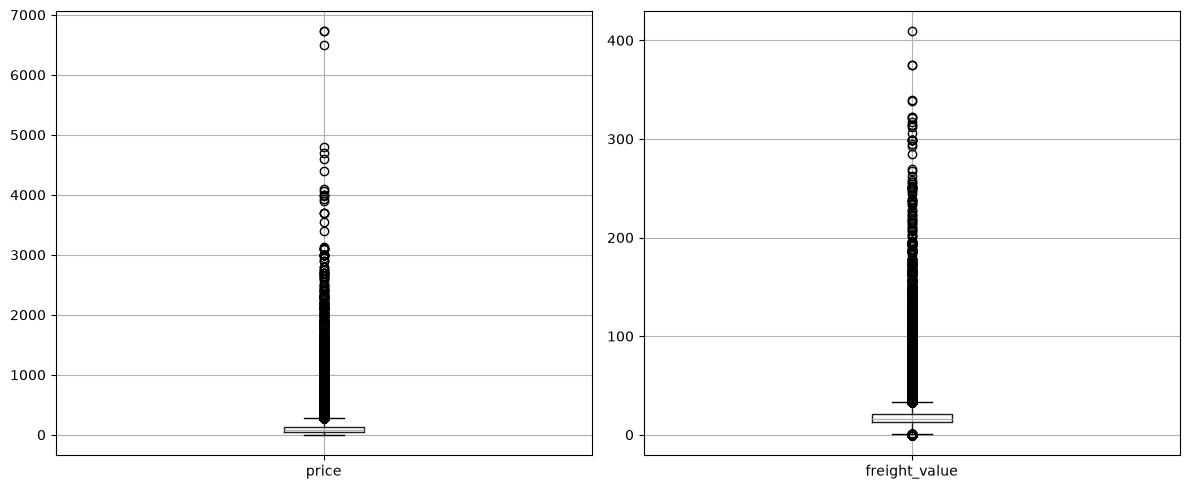

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
df3.boxplot(column="price", ax=axes[0])
df3.boxplot(column="freight_value", ax=axes[1])
plt.tight_layout()
plt.show()